# Imports

In [11]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split

# Loading Images and Preparing Data

In [3]:
alcohol_normal_cases = "/content/drive/MyDrive/dataset/HOD benchmark/class/alcohol/normal_cases/jpg"
alcohol_hard_cases = "/content/drive/MyDrive/dataset/HOD benchmark/class/alcohol/hard_cases/jpg"

blood_normal_cases = "/content/drive/MyDrive/dataset/HOD benchmark/class/blood/normal_cases/jpg"
blood_hard_cases = "/content/drive/MyDrive/dataset/HOD benchmark/class/blood/hard_cases/jpg"

cigarette_normal_cases = "/content/drive/MyDrive/dataset/HOD benchmark/class/cigarette/normal_cases/jpg"
cigarette_hard_cases = "/content/drive/MyDrive/dataset/HOD benchmark/class/cigarette/hard_cases/jpg"

gun_normal_cases = "/content/drive/MyDrive/dataset/HOD benchmark/class/gun/normal_cases/jpg"
gun_hard_cases = "/content/drive/MyDrive/dataset/HOD benchmark/class/gun/hard_cases/jpg"

gestures_normal_cases = "/content/drive/MyDrive/dataset/HOD benchmark/class/insulting_gesture/normal_cases/jpg"
gestures_hard_cases = "/content/drive/MyDrive/dataset/HOD benchmark/class/insulting_gesture/hard_cases/jpg"

knife_normal_cases = "/content/drive/MyDrive/dataset/HOD benchmark/class/knife/normal_cases/jpg"
knife_hard_cases = "/content/drive/MyDrive/dataset/HOD benchmark/class/knife/hard_cases/jpg"

alcohol_images = [alcohol_normal_cases, alcohol_hard_cases]
non_alcohol_images = [blood_normal_cases, blood_hard_cases, cigarette_normal_cases, cigarette_hard_cases, \
                      gun_normal_cases, gun_hard_cases, gestures_normal_cases, gestures_hard_cases, \
                      knife_normal_cases, knife_hard_cases]

In [4]:
data = []

def add_images(directories, label):
    """ function to add images to the dataset """
    for directory in directories:
        for filename in os.listdir(directory):
            file_path = os.path.join(directory, filename)
            data.append([file_path, label])

# adding alcohol and non-alcohol images to the dataset
add_images(alcohol_images, "alcohol")
add_images(non_alcohol_images, "non_alcohol")

# creating a DataFrame
df = pd.DataFrame(data, columns=["image_path", "label"])

# shuffling the dataset to mix alcohol and non-alcohol images
df = df.sample(frac = 1).reset_index(drop = True)

print(df.head())

                                          image_path        label
0  /content/drive/MyDrive/dataset/HOD benchmark/c...  non_alcohol
1  /content/drive/MyDrive/dataset/HOD benchmark/c...  non_alcohol
2  /content/drive/MyDrive/dataset/HOD benchmark/c...  non_alcohol
3  /content/drive/MyDrive/dataset/HOD benchmark/c...  non_alcohol
4  /content/drive/MyDrive/dataset/HOD benchmark/c...  non_alcohol


In [5]:
# splitting the DataFrame into training and validation sets
train_df, val_df = train_test_split(df, test_size = 0.2)

# data generators
train_datagen = ImageDataGenerator(
    rescale = 1./255,
    rotation_range = 40,
    width_shift_range = 0.2,
    height_shift_range = 0.2,
    shear_range = 0.2,
    zoom_range = 0.2,
    horizontal_flip = True,
    fill_mode = "nearest"
)

val_datagen = ImageDataGenerator(rescale = 1./255)

# using a smaller subset for faster training
train_subset = train_df.sample(frac = 0.1)
val_subset = val_df.sample(frac = 0.1)

# generators
train_generator_subset = train_datagen.flow_from_dataframe(
    dataframe = train_subset,
    x_col = "image_path",
    y_col = "label",
    target_size = (160, 160),
    batch_size = 32,
    class_mode = "binary"
)

val_generator_subset = val_datagen.flow_from_dataframe(
    dataframe = val_subset,
    x_col = "image_path",
    y_col = "label",
    target_size = (160, 160),
    batch_size = 32,
    class_mode = "binary"
)

Found 8504 validated image filenames belonging to 2 classes.
Found 2127 validated image filenames belonging to 2 classes.


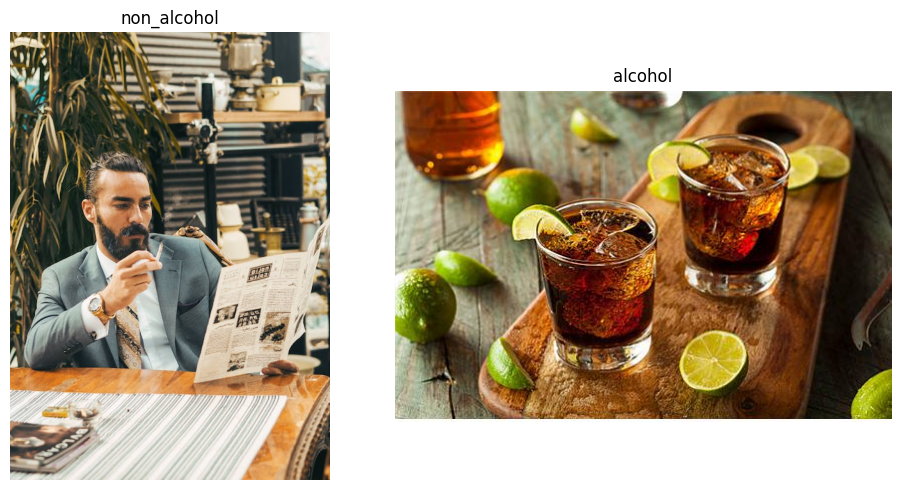

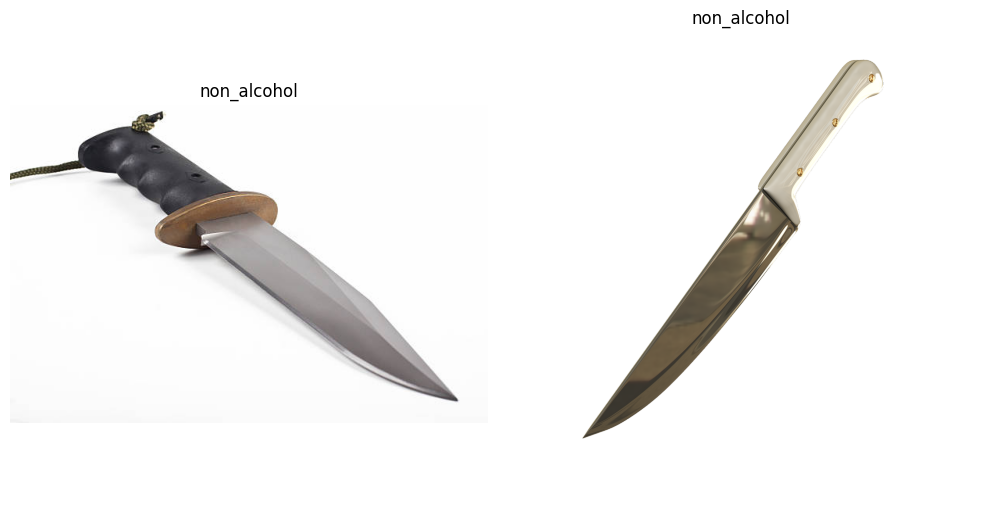

In [18]:
def plot_sample_images(dataframe, num_images=2):
    fig, axes = plt.subplots(1, num_images, figsize=(10, 5))
    for ax, (index, row) in zip(axes, dataframe.sample(num_images).iterrows()):
        img_path = row['image_path']
        label = row['label']
        image = Image.open(img_path)
        ax.imshow(image)
        ax.set_title(label)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

# plotting a couple of images from the training subset
plot_sample_images(train_subset, num_images = 2)

# plotting a couple from the validation subset
plot_sample_images(val_subset, num_images = 2)

# Creating a Model

In [6]:
# loading MobileNetV2
base_model = tf.keras.applications.MobileNetV2(input_shape = (160, 160, 3),
                                               include_top = False,
                                               weights = "imagenet")

# freezing the base model
base_model.trainable = False

# adding a classification head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation = "relu")(x)
predictions = Dense(1, activation = "sigmoid")(x)

model = Model(inputs = base_model.input, outputs = predictions)

# compiling the model
model.compile(optimizer = tf.keras.optimizers.Adam(),
              loss = "binary_crossentropy",
              metrics = ["accuracy"])

# Training the Model

In [7]:
history_subset = model.fit(
    train_generator_subset,
    steps_per_epoch = train_generator_subset.samples // train_generator_subset.batch_size,
    validation_data = val_generator_subset,
    validation_steps = val_generator_subset.samples // val_generator_subset.batch_size,
    epochs = 10
)

Found 850 validated image filenames belonging to 2 classes.
Found 213 validated image filenames belonging to 2 classes.
Epoch 1/10
26/26 [==============================] - 242s 9s/step - loss: 0.6604 - accuracy: 0.8472 - val_loss: 0.3154 - val_accuracy: 0.8802
Epoch 2/10
26/26 [==============================] - 39s 1s/step - loss: 0.1964 - accuracy: 0.9254 - val_loss: 0.1554 - val_accuracy: 0.9427
Epoch 3/10
26/26 [==============================] - 34s 1s/step - loss: 0.1724 - accuracy: 0.9303 - val_loss: 0.1517 - val_accuracy: 0.9479
Epoch 4/10
26/26 [==============================] - 33s 1s/step - loss: 0.1363 - accuracy: 0.9411 - val_loss: 0.1566 - val_accuracy: 0.9479
Epoch 5/10
26/26 [==============================] - 34s 1s/step - loss: 0.1328 - accuracy: 0.9487 - val_loss: 0.1321 - val_accuracy: 0.9531
Epoch 6/10
26/26 [==============================] - 33s 1s/step - loss: 0.1087 - accuracy: 0.9597 - val_loss: 0.1375 - val_accuracy: 0.9479
Epoch 7/10
26/26 [=====================

# Results Visualization

1/1 [==============================] - 1s 526ms/step


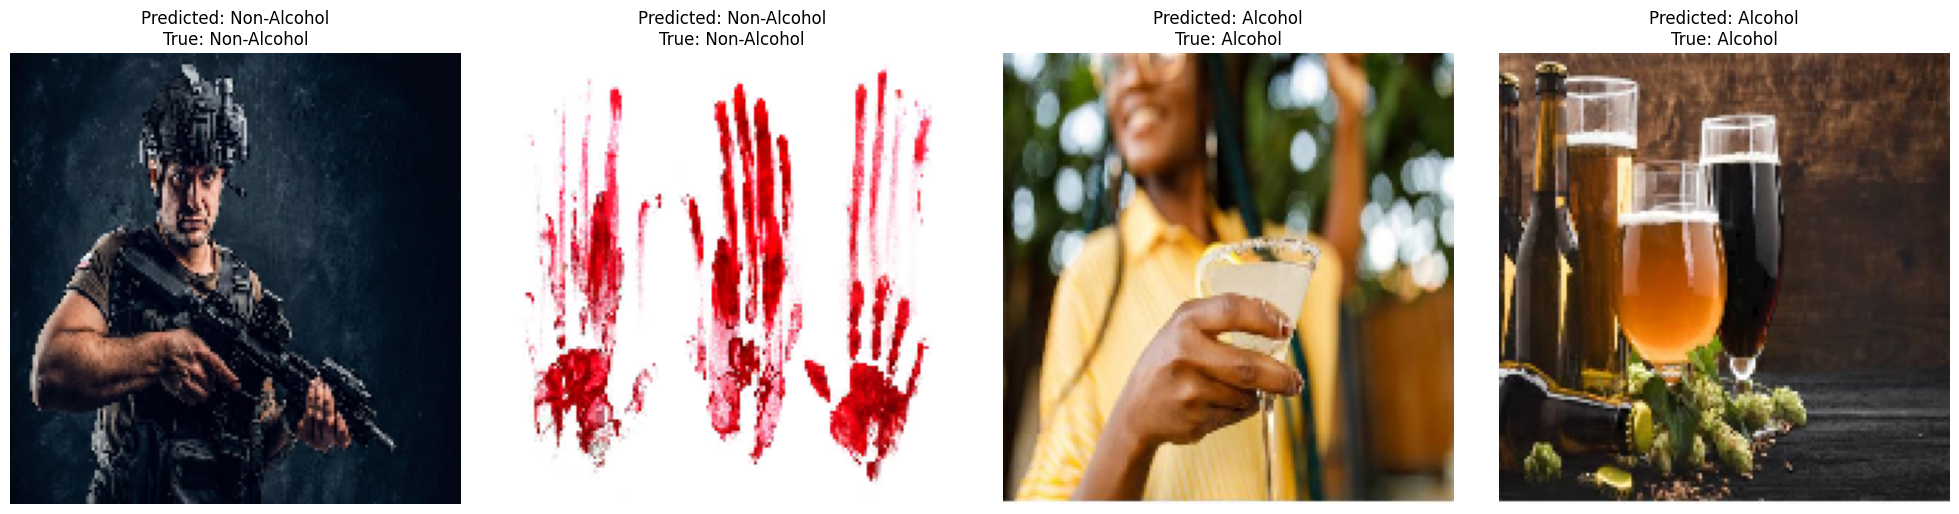

In [22]:
def predict_and_visualize_examples(generator, model, num_examples=4):
    # getting a batch of images from the generator
    for x_batch, y_batch in generator:
        break

    # making predictions
    predictions = model.predict(x_batch)

    # converting predictions to binary labels
    predictions = predictions.flatten()
    predicted_labels = (predictions > 0.5).astype(int)


    # plotting the images and their predicted labels
    fig, axes = plt.subplots(1, num_examples * 2, figsize = (20, 5))
    count_true = 0
    count_false = 0

    for i, (img, label, pred_label) in enumerate(zip(x_batch, y_batch, predicted_labels)):
        if count_true < num_examples and pred_label == 1:
            ax = axes[count_true]
            ax.imshow(img)
            ax.set_title(f'Predicted: {"Non-Alcohol" if pred_label == 1 else "Alcohol"}\nTrue: {"Non-Alcohol" if label == 1 else "Alcohol"}')
            ax.axis('off')
            count_true += 1
        elif count_false < num_examples and pred_label == 0:
            ax = axes[num_examples + count_false]
            ax.imshow(img)
            ax.set_title(f'Predicted: {"Non-Alcohol" if pred_label == 1 else "Alcohol"}\nTrue: {"Non-Alcohol" if label == 1 else "Alcohol"}')
            ax.axis('off')
            count_false += 1

        if count_true >= num_examples and count_false >= num_examples:
            break

    plt.tight_layout()
    plt.show()

# using the validation generator but make sure to reset it to ensure we're starting from the beginning
val_generator_subset.reset()
predict_and_visualize_examples(val_generator_subset, model, num_examples = 2)